# 02 - Statistical Analysis (SYNTHETIC data)
Each section: **concept first, then code, then interpretation.** Results are written to `reports/results/statistics.json`
and nothing is hand-typed into the report. Significance level alpha = 0.05 throughout, with a Holm correction across the
four hypothesis tests (so we do not "find" significance just by running many tests).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

from src.data_access import load_tables
from src.analytics.common import setup, save_fig, save_results, banner
from src.modelling.features import loan_frame

setup(); banner()
rng = np.random.default_rng(42)
t = load_tables()
df = loan_frame(t)
mature = df[df.months_on_book >= 15].copy()
res = {}

ALL DATA IN THIS PROJECT IS SYNTHETIC. Findings describe the simulation, not real lending.


[data] loaded from PostgreSQL (analytics schema)


## 1. Descriptive statistics: mean, median, mode, variance, standard deviation
* **Mean** = arithmetic average, pulled up by large values. **Median** = middle value, robust to outliers.
  **Mode** = most frequent value (meaningful for discrete data such as tenure).
* **Variance** = average squared distance from the mean; **standard deviation (SD)** = its square root, in the original units.
* **Coefficient of variation (CV = SD/mean)** compares spread across variables with different units.
Right-skewed money variables have mean > median; that gap is the practical reason to report the median for income and loan size.

In [2]:
rows = {}
for c in ["loan_amount", "monthly_income", "interest_rate", "credit_score", "foir"]:
    s = df[c].dropna()
    rows[c] = dict(mean=s.mean(), median=s.median(), sd=s.std(ddof=1), variance=s.var(ddof=1), cv=s.std(ddof=1) / s.mean(), skew=s.skew())
desc = pd.DataFrame(rows).T
print(desc.round(3))
print("Mode of tenure_months:", int(df.tenure_months.mode().iloc[0]), "| tenure distribution (%):",
      (df.tenure_months.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())
res["descriptive"] = desc.round(4).to_dict("index")
res["tenure_mode"] = int(df.tenure_months.mode().iloc[0])

                      mean     median          sd      variance     cv   skew
loan_amount     149669.962  117000.00  117514.942  1.380976e+10  0.785  2.273
monthly_income   44206.552   38900.00   24101.907  5.809019e+08  0.545  1.850
interest_rate       16.894      16.81       3.752  1.407800e+01  0.222  0.206
credit_score       718.037     718.00      59.767  3.572052e+03  0.083 -0.020
foir                 0.451       0.41       0.258  6.600000e-02  0.572  1.202
Mode of tenure_months: 12 | tenure distribution (%): {6.0: 10.0, 9.0: 12.0, 12.0: 29.6, 18.0: 15.2, 24.0: 20.3, 36.0: 13.0}


## 2. Sampling and the Central Limit Theorem
We rarely observe a whole population. A **sample mean** varies from sample to sample; its spread is the **standard error**
(SE = SD/sqrt(n)). The CLT says the distribution of sample means approaches a normal curve as n grows, *even if the data is skewed*.
Demonstration: treat our 20K loans as the "population", draw 2,000 samples at several sizes, and compare SD of sample means to SD/sqrt(n).

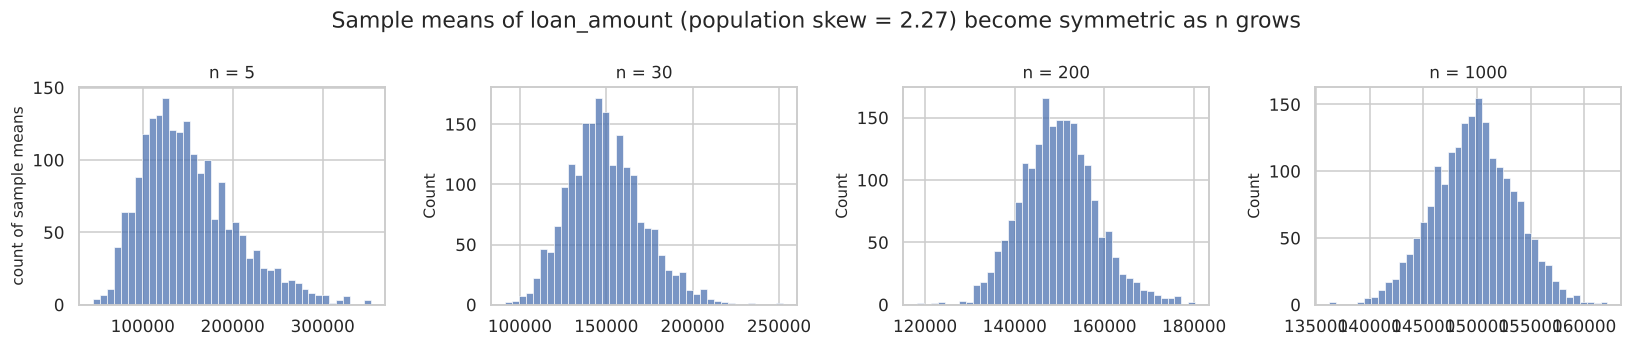

      sd_of_sample_means  theoretical_se  skew_of_means
5              51841.435       52554.280          0.811
30             21321.347       21455.195          0.423
200             8378.732        8309.561          0.266
1000            3762.373        3716.149         -0.003


In [3]:
pop = df.loan_amount.to_numpy()
clt = {}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=False)
for ax, n in zip(axes, [5, 30, 200, 1000]):
    means = np.array([rng.choice(pop, n, replace=True).mean() for _ in range(2000)])
    clt[n] = dict(sd_of_sample_means=means.std(ddof=1), theoretical_se=pop.std(ddof=1) / np.sqrt(n), skew_of_means=float(stats.skew(means)))
    sns.histplot(means, bins=40, ax=ax, color="#4c72b0"); ax.set_title(f"n = {n}")
axes[0].set_ylabel("count of sample means")
fig.suptitle(f"Sample means of loan_amount (population skew = {stats.skew(pop):.2f}) become symmetric as n grows")
save_fig(fig, "stats_clt")
print(pd.DataFrame(clt).T.round(3))
res["clt"] = {str(k): v for k, v in clt.items()}

## 3. Probability distributions: do the data look like the textbook shapes?
* **Binomial**: number of defaults among n loans when each defaults with probability p (assumes independence).
* **Normal**: symmetric bell; credit score is roughly normal by design.
* **Log-normal**: log of the variable is normal; typical for incomes and loan sizes.
We check with a Shapiro-Wilk test on a random subsample (the test is hypersensitive on big samples, so we also look at skew).

                shapiro_p_raw  shapiro_p_log  skew_raw  skew_log
credit_score            0.092         0.0000   -0.0414   -0.3010
monthly_income          0.000         0.0000    1.6809    0.0653
loan_amount             0.000         0.1557    2.1253   -0.0125
Binomial(n=500, p=0.0860): mean=43.0, 95% of batches have 31-56 defaults


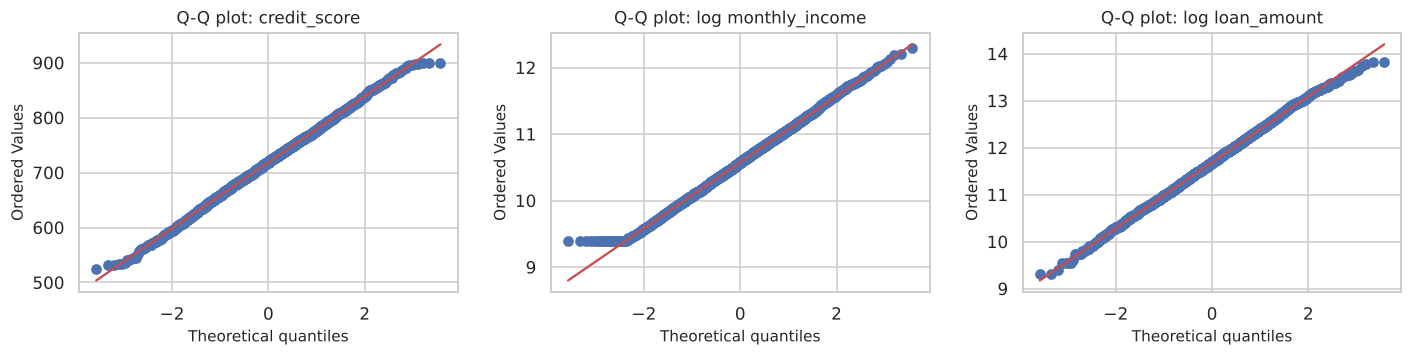

In [4]:
sub = df.sample(4000, random_state=42)
dist = {}
for c in ["credit_score", "monthly_income", "loan_amount"]:
    x = sub[c].dropna()
    dist[c] = dict(shapiro_p_raw=float(stats.shapiro(x).pvalue), shapiro_p_log=float(stats.shapiro(np.log(x)).pvalue),
                   skew_raw=float(stats.skew(x)), skew_log=float(stats.skew(np.log(x))))
print(pd.DataFrame(dist).T.round(4))
res["distribution_checks"] = dist
# Binomial: with the observed mature default rate p, how many defaults would we expect in 500 loans?
p_hat = mature.is_default.mean(); n_b = 500
binom = stats.binom(n_b, p_hat)
lo, hi = binom.ppf([0.025, 0.975])
print(f"Binomial(n=500, p={p_hat:.4f}): mean={binom.mean():.1f}, 95% of batches have {int(lo)}-{int(hi)} defaults")
res["binomial_example"] = dict(n=n_b, p=float(p_hat), mean=float(binom.mean()), central95=[int(lo), int(hi)])
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, c in zip(axes, ["credit_score", "monthly_income", "loan_amount"]):
    stats.probplot(np.log(sub[c].dropna()) if c != "credit_score" else sub[c].dropna(), dist="norm", plot=ax)
    ax.set_title(f"Q-Q plot: {'log ' if c != 'credit_score' else ''}{c}")
save_fig(fig, "stats_qq")

## 4. Confidence intervals
A 95% CI is produced by a procedure that captures the true value in 95% of repeated samples. It is **not** "95% probability the true value is in this
interval". For a proportion we use the **Wilson interval** (better than the textbook normal interval for small samples/rates near 0);
for a mean we use the **t-interval** and a **bootstrap** as a check.

Overall default rate (mature loans): 891/10364 = 8.5971%, 95% Wilson CI [8.0726%, 9.1522%]
Mean loan amount: 149,670  t-CI [148,047, 151,293]  bootstrap CI [148,085, 151,343]
                      n   rate  ci_low  ci_high
Gig Worker       1381.0  15.06   13.27    17.04
Contract Worker   770.0  11.82    9.73    14.29
Self-Employed    2084.0   9.93    8.72    11.29
Unknown           140.0   9.29    5.51    15.24
Business Owner   1003.0   7.58    6.10     9.38
Salaried         4986.0   5.94    5.31     6.63


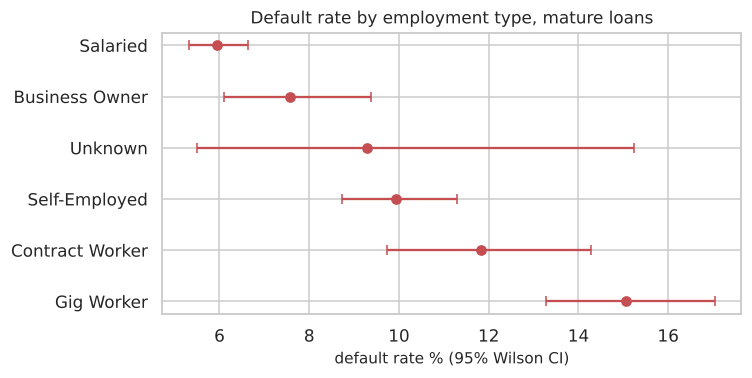

In [5]:
k, n = int(mature.is_default.sum()), len(mature)
wil = proportion_confint(k, n, alpha=0.05, method="wilson")
print(f"Overall default rate (mature loans): {k}/{n} = {k/n:.4%}, 95% Wilson CI [{wil[0]:.4%}, {wil[1]:.4%}]")
x = df.loan_amount
t_ci = stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))
boot = np.array([rng.choice(x.to_numpy(), len(x)).mean() for _ in range(2000)])
print(f"Mean loan amount: {x.mean():,.0f}  t-CI [{t_ci[0]:,.0f}, {t_ci[1]:,.0f}]  bootstrap CI [{np.percentile(boot, 2.5):,.0f}, {np.percentile(boot, 97.5):,.0f}]")
seg_ci = {}
for emp, g in mature.groupby("employment_type"):
    kk, nn = int(g.is_default.sum()), len(g); a, b = proportion_confint(kk, nn, method="wilson")
    seg_ci[emp] = dict(n=nn, rate=kk / nn, ci_low=a, ci_high=b)
seg_ci = pd.DataFrame(seg_ci).T.sort_values("rate", ascending=False)
print((seg_ci.assign(rate=lambda d: d.rate * 100, ci_low=lambda d: d.ci_low * 100, ci_high=lambda d: d.ci_high * 100)).round(2))
res["ci"] = dict(overall_default=dict(k=k, n=n, rate=k / n, wilson=list(wil)),
                 mean_loan=dict(mean=float(x.mean()), t_ci=list(t_ci), boot_ci=[float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))]),
                 by_employment=seg_ci.to_dict("index"))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(seg_ci.rate * 100, range(len(seg_ci)), xerr=[(seg_ci.rate - seg_ci.ci_low) * 100, (seg_ci.ci_high - seg_ci.rate) * 100], fmt="o", color="#c44e52", capsize=3)
ax.set_yticks(range(len(seg_ci))); ax.set_yticklabels(seg_ci.index); ax.set_xlabel("default rate % (95% Wilson CI)"); ax.set_title("Default rate by employment type, mature loans")
save_fig(fig, "stats_ci_employment")

## 5. Correlation
* **Pearson r**: linear association; sensitive to outliers. **Spearman rho**: rank-based, monotone association, robust.
* With a binary outcome the Pearson value is the *point-biserial* correlation. Correlation is **not causation** and says nothing about direction.
* With n ~ 10K even tiny correlations are "significant", so we focus on effect size (|r|), not p-values.

                        pearson_r  spearman_rho  spearman_p
loan_to_income             0.2689        0.2080      0.0000
foir                       0.2695        0.2025      0.0000
credit_score              -0.1878       -0.1807      0.0000
interest_rate              0.1772        0.1683      0.0000
loan_amount                0.1356        0.1209      0.0000
credit_utilization_pct     0.0619        0.0598      0.0000
tenure_months             -0.0436       -0.0521      0.0000
monthly_income            -0.0466       -0.0488      0.0000
age                       -0.0367       -0.0368      0.0002


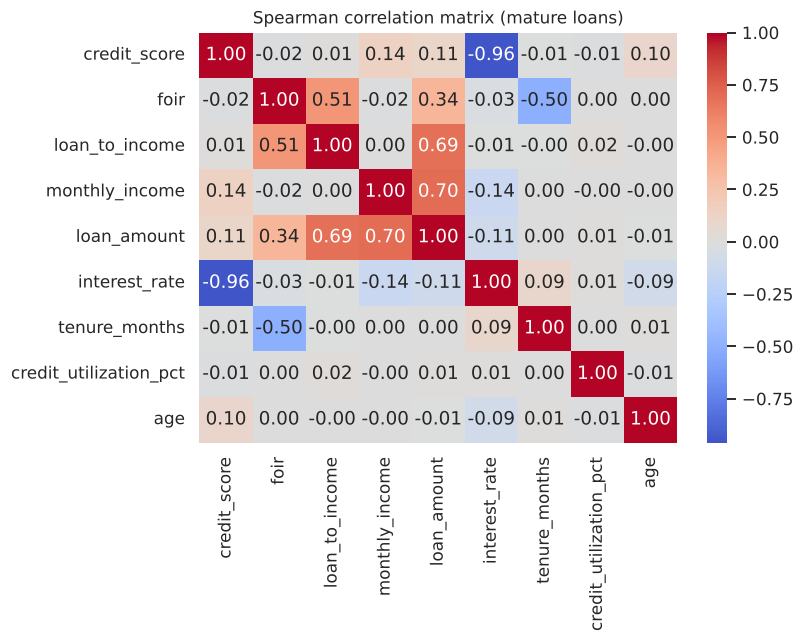

Note: interest_rate is mechanically linked to credit_score (pricing rule) - correlated predictors share information.


In [6]:
cols = ["credit_score", "foir", "loan_to_income", "monthly_income", "loan_amount", "interest_rate", "tenure_months", "credit_utilization_pct", "age"]
sp = {c: stats.spearmanr(mature[c], mature.is_default, nan_policy="omit") for c in cols}
pe = {c: stats.pearsonr(*mature[[c, "is_default"]].dropna().T.to_numpy()) for c in cols}
corr = pd.DataFrame({"pearson_r": {c: v[0] for c, v in pe.items()}, "spearman_rho": {c: v[0] for c, v in sp.items()},
                     "spearman_p": {c: v[1] for c, v in sp.items()}}).sort_values("spearman_rho", key=abs, ascending=False)
print(corr.round(4))
res["correlation_with_default"] = corr.round(5).to_dict("index")
cm = mature[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6)); sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax); ax.set_title("Spearman correlation matrix (mature loans)")
save_fig(fig, "stats_corr_heatmap")
print("Note: interest_rate is mechanically linked to credit_score (pricing rule) - correlated predictors share information.")

# Hypothesis tests
**Framework.** State H0 (no effect) and H1; choose a test whose assumptions hold; compute a **p-value** = probability of seeing a result at least this
extreme *if H0 were true*. A small p-value is evidence against H0; it is **not** the probability H0 is true, and says nothing about effect *size*,
so we always report an effect size and CI. We apply a Holm correction across the 4 tests.

### H1 - Gig workers vs salaried: default rate
* H0: default rate is equal. H1: they differ (two-sided).
* Test: **two-proportion z-test** (independent groups, large counts; expected counts >> 5 checked below). Effect size: rate difference and risk ratio with 95% CI.
* Limitation: observational; gig workers also differ on income, credit score etc. (confounding). H4 adjusts for some of that.

In [7]:
def two_prop(a, b, label_a, label_b):
    ka, na, kb, nb = int(a.sum()), len(a), int(b.sum()), len(b)
    z, p = proportions_ztest([ka, kb], [na, nb])
    lo, hi = confint_proportions_2indep(ka, na, kb, nb, method="wald")
    exp_min = min(na * (ka + kb) / (na + nb), na * (1 - (ka + kb) / (na + nb)), nb * (ka + kb) / (na + nb), nb * (1 - (ka + kb) / (na + nb)))
    rr = (ka / na) / (kb / nb)
    se_log_rr = np.sqrt(1 / ka - 1 / na + 1 / kb - 1 / nb)
    return dict(group_a=label_a, group_b=label_b, n_a=na, n_b=nb, rate_a=ka / na, rate_b=kb / nb, diff=ka / na - kb / nb,
                diff_ci=[float(lo), float(hi)], risk_ratio=rr, rr_ci=[float(np.exp(np.log(rr) - 1.96 * se_log_rr)), float(np.exp(np.log(rr) + 1.96 * se_log_rr))],
                z=float(z), p_value=float(p), min_expected_count=float(exp_min))

h1 = two_prop(mature[mature.employment_type == "Gig Worker"].is_default, mature[mature.employment_type == "Salaried"].is_default, "Gig Worker", "Salaried")
print(pd.Series(h1))

group_a                                               Gig Worker
group_b                                                 Salaried
n_a                                                         1381
n_b                                                         4986
rate_a                                                  0.150615
rate_b                                                  0.059366
diff                                                    0.091249
diff_ci               [0.07127726211339794, 0.11122127905894474]
risk_ratio                                              2.537057
rr_ci                   [2.1468156194229246, 2.9982351587063936]
z                                                      11.114619
p_value                                                      0.0
min_expected_count                                    109.317418
dtype: object


### H2 - Gender and default (a deliberate sanity check)
* H0: default rate is the same across genders. H1: it differs.
* Test: **chi-square test of independence** on the 3x2 table (Male/Female/Other). "Other" is tiny; we report it but the test is run on Male vs Female
  as the primary comparison because expected counts for "Other" are too small for chi-square validity.
* In this simulation gender has **no designed effect**. If the test is not significant that is the *expected, honest* result and we do not hunt for one.
  (If this were real data, using gender in credit decisions would also raise legal and fairness issues in many jurisdictions.)

In [8]:
mf = mature[mature.gender.isin(["Male", "Female"])]
ct = pd.crosstab(mf.gender, mf.is_default)
chi2, p2, dof, exp = stats.chi2_contingency(ct, correction=False)
h2 = two_prop(mf[mf.gender == "Female"].is_default, mf[mf.gender == "Male"].is_default, "Female", "Male")
h2.update(chi2=float(chi2), dof=int(dof), p_value=float(p2), min_expected_count=float(exp.min()),
          other_group=dict(n=int((mature.gender == "Other").sum()), defaults=int(mature[mature.gender == "Other"].is_default.sum())))
print(pd.Series(h2))

group_a                                                      Female
group_b                                                        Male
n_a                                                            3733
n_b                                                            6515
rate_a                                                     0.082239
rate_b                                                     0.088258
diff                                                      -0.006018
diff_ci               [-0.017203901465330875, 0.005167139878035878]
risk_ratio                                                 0.931809
rr_ci                      [0.8161146124509279, 1.0639047990236912]
z                                                          -1.04538
p_value                                                    0.295848
min_expected_count                                       321.282787
chi2                                                       1.092819
dof                                             

### H3 - Are newer cohorts riskier? (repayment patterns changing over time)
* H0: the share of loans reaching 30+ DPD within the first 6 instalments is the same for older (disbursed Jul-2023..Jun-2024) and newer
  (Jul-2024..Sep-2025) cohorts. H1: it differs.
* Test: two-proportion z-test. We use the "30+ DPD in first 6 instalments" outcome (not 'default') because it is observable for much more recent loans,
  avoiding right-censoring. Effect size reported as above.
* Limitation: portfolio mix also changes (more gig/Tier-3 etc.), so a difference could be a mix shift rather than worse underwriting of the same people. H4 adjusts.

In [9]:
first6 = t["repayments"][t["repayments"].installment_no <= 6].groupby("loan_id").dpd.max().rename("max_dpd_first6")
c7 = df[df.months_on_book >= 7].merge(first6, left_on="loan_id", right_index=True)
c7["hit30"] = (c7.max_dpd_first6 >= 30).astype(int)
old = c7[(c7.disbursement_date >= "2023-07-01") & (c7.disbursement_date < "2024-07-01")]
new = c7[(c7.disbursement_date >= "2024-07-01") & (c7.disbursement_date < "2025-10-01")]
h3 = two_prop(new.hit30, old.hit30, "New cohorts (Jul24-Sep25)", "Old cohorts (Jul23-Jun24)")
print(pd.Series(h3))

group_a                                  New cohorts (Jul24-Sep25)
group_b                                  Old cohorts (Jul23-Jun24)
n_a                                                           9931
n_b                                                           4945
rate_a                                                     0.12466
rate_b                                                    0.106572
diff                                                      0.018088
diff_ci               [0.007309386083727219, 0.028866333560788576]
risk_ratio                                                1.169724
rr_ci                     [1.0625804408969044, 1.2876708653259052]
z                                                         3.213806
p_value                                                    0.00131
min_expected_count                                      586.711818
dtype: object


### H4 - Do defaulters have lower credit scores? (non-parametric + adjusted model)
* H0: credit-score distributions of defaulted and non-defaulted mature loans are the same. H1: defaulters' scores are lower (one-sided).
* Test: **Mann-Whitney U** (rank-based; no normality assumption) plus **Welch t-test** as a cross-check (does not assume equal variances).
  Effect size: Cohen's d and the probability of superiority (AUC = U/(n1*n2)).
* Then a **multivariable logistic regression** estimates the credit-score association *after adjusting* for other risk factors.

In [10]:
d_ = mature[mature.is_default == 1].credit_score.dropna(); n_ = mature[mature.is_default == 0].credit_score.dropna()
u = stats.mannwhitneyu(d_, n_, alternative="less")
w = stats.ttest_ind(d_, n_, equal_var=False, alternative="less")
pooled = np.sqrt(((len(d_) - 1) * d_.var(ddof=1) + (len(n_) - 1) * n_.var(ddof=1)) / (len(d_) + len(n_) - 2))
h4 = dict(n_default=len(d_), n_nondefault=len(n_), mean_default=float(d_.mean()), mean_nondefault=float(n_.mean()),
          median_default=float(d_.median()), median_nondefault=float(n_.median()), mannwhitney_U=float(u.statistic), p_value=float(u.pvalue),
          welch_t=float(w.statistic), welch_p=float(w.pvalue), cohens_d=float((d_.mean() - n_.mean()) / pooled),
          prob_superiority_auc=float(1 - u.statistic / (len(d_) * len(n_))))
print(pd.Series(h4))

n_default               8.820000e+02
n_nondefault            9.354000e+03
mean_default            6.806440e+02
mean_nondefault         7.208199e+02
median_default          6.810000e+02
median_nondefault       7.210000e+02
mannwhitney_U           2.591288e+06
p_value                 5.626859e-75
welch_t                -1.970876e+01
welch_p                 3.052272e-74
cohens_d               -6.812558e-01
prob_superiority_auc    6.859132e-01
dtype: float64


In [11]:
m = mature.dropna(subset=["credit_score", "monthly_income"]).copy()
m["cohort_year_after_2024h2"] = (m.disbursement_date >= "2024-07-01").astype(int)
m["credit_score_100"] = (m.credit_score - 700) / 100
m["foir_10pp"] = m.foir * 10
m["util_10pp"] = m.credit_utilization_pct / 10
logit = smf.logit("is_default ~ credit_score_100 + foir_10pp + util_10pp + C(employment_type, Treatment('Salaried')) + C(city_tier) + "
                  "C(acquisition_channel, Treatment('Organic')) + C(gender) + previous_loans_count + tenure_months + cohort_year_after_2024h2",
                  data=m).fit(disp=0)
orr = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(logit.conf_int()[0]), "ci_high": np.exp(logit.conf_int()[1]), "p": logit.pvalues})
orr.index = [i.replace("C(employment_type, Treatment('Salaried'))", "emp").replace("C(acquisition_channel, Treatment('Organic'))", "chan") for i in orr.index]
print(orr.round(3)); print("pseudo R2 (McFadden):", round(logit.prsquared, 4), "| n =", int(logit.nobs))
res["logit_adjusted_odds_ratios"] = orr.round(4).to_dict("index")
res["logit_n"] = int(logit.nobs)

                           odds_ratio  ci_low  ci_high      p
Intercept                       0.002   0.001    0.003  0.000
emp[T.Business Owner]           1.072   0.805    1.428  0.636
emp[T.Contract Worker]          1.240   0.933    1.647  0.138
emp[T.Gig Worker]               1.559   1.247    1.948  0.000
emp[T.Self-Employed]            1.368   1.113    1.680  0.003
emp[T.Unknown]                  1.189   0.611    2.314  0.610
C(city_tier)[T.Tier 2]          1.079   0.902    1.291  0.407
C(city_tier)[T.Tier 3]          1.378   1.140    1.666  0.001
chan[T.Customer Referral]       1.064   0.839    1.350  0.607
chan[T.Paid Digital]            1.456   1.201    1.766  0.000
chan[T.Partner Referral]        1.509   1.226    1.857  0.000
C(gender)[T.Male]               1.014   0.864    1.190  0.862
C(gender)[T.Other]              0.840   0.399    1.768  0.646
credit_score_100                0.318   0.276    0.368  0.000
foir_10pp                       1.459   1.415    1.504  0.000
util_10p

pseudo R2 (McFadden): 0.195 | n = 10107


## Multiple-testing correction and summary

In [12]:
tests = {"H1 gig vs salaried default rate": h1, "H2 gender (female vs male) default rate": h2, "H3 newer vs older cohorts 30+DPD in first 6": h3, "H4 credit score lower in defaulters": h4}
pvals = [v["p_value"] for v in tests.values()]
reject, p_adj, _, _ = multipletests(pvals, alpha=0.05, method="holm")
summary = pd.DataFrame({"test": list(tests), "p_raw": pvals, "p_holm": p_adj, "reject_H0_at_5pct": reject})
print(summary.to_string(index=False))
res["hypotheses"] = dict(H1=h1, H2=h2, H3=h3, H4=h4)
res["holm_summary"] = summary.to_dict("records")
save_results("statistics", res)

                                       test        p_raw       p_holm  reject_H0_at_5pct
            H1 gig vs salaried default rate 1.065040e-28 3.195121e-28               True
    H2 gender (female vs male) default rate 2.958475e-01 2.958475e-01              False
H3 newer vs older cohorts 30+DPD in first 6 1.309882e-03 2.619764e-03               True
        H4 credit score lower in defaulters 5.626859e-75 2.250744e-74               True


[saved] reports/results/statistics.json


PosixPath('/home/claude/FinSight/reports/results/statistics.json')

### How to read the results (limitations)
* Statistical significance != business importance: always read the effect size and CI alongside p.
* All tests are **observational** on **synthetic** data: they show association, not causation, and the effects found are those the simulation was built with.
* Loans from the same customer are not fully independent (repeat borrowers), a mild violation of the independence assumption.
* Tests use mature loans (>= 15 months) for default, which is a selected, older subset of the portfolio.